# Sizing a site with Monte Carlo runs

How many charging points does a site need? Every configuration is simulated with
20 independent seeds; bands show the 5th-95th percentile across seeds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import elvis

plt.style.use("paper.mplstyle")
FIGURES = Path("output/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
GRID = elvis.TimeGrid.create("2024-04-01", "2024-04-28 23:45", "15min")
SEEDS = range(20)
POINTS = [4, 6, 8, 10, 14, 18, 24, 30, 40]
SITES = {"office": "Office", "park_and_ride": "Park & ride", "roadside": "Roadside"}


def rejection_rates(preset, points):
    scenario = elvis.load_preset(preset)
    point_kw = scenario.infrastructure.charging_points[0].max_power_kw
    sized = scenario.replace(infrastructure=elvis.InfrastructureSpec.wallboxes(points, point_kw))
    return [elvis.simulate(sized.realise(GRID, seed)).rejection_rate for seed in SEEDS]


rejection = {
    preset: np.array([rejection_rates(preset, n) for n in POINTS]) * 100 for preset in SITES
}

In [3]:
office = elvis.load_preset("office")
transformer_kw = np.array([15, 20, 25, 30, 40, 50, 60, 74])
points = np.array([10, 15, 20, 25, 30])


def mean_power(points, transformer):
    site = office.replace(
        infrastructure=elvis.InfrastructureSpec.wallboxes(
            points, 3.7, transformer_power_kw=transformer
        ),
        operation=elvis.Operation(scheduling="fcfs"),
    )
    runs = [elvis.simulate(site.realise(GRID, seed)) for seed in range(5)]
    return np.mean([r.total_energy_kwh for r in runs]) / GRID.duration_hours


energy = np.array([[mean_power(n, t) for t in transformer_kw] for n in points])

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


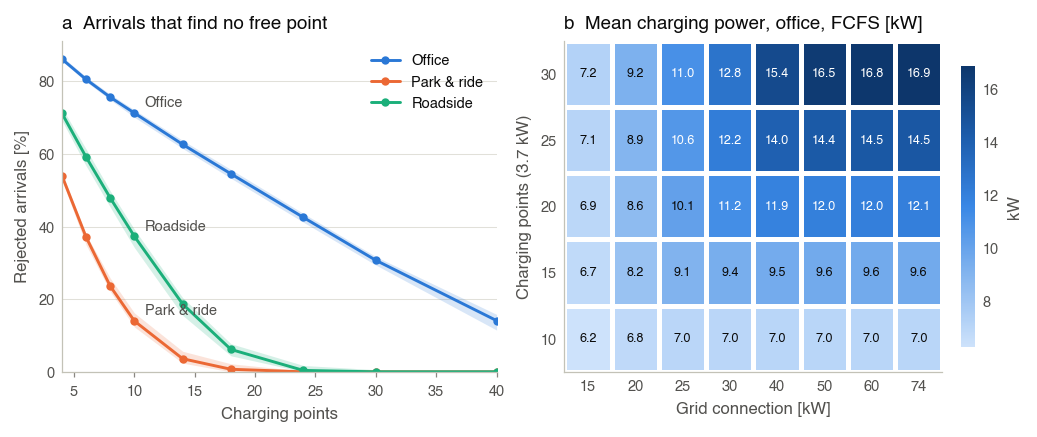

In [4]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

fig, (ax_rej, ax_map) = plt.subplots(1, 2, width_ratios=[1.15, 1])

for (preset, label), color in zip(SITES.items(), ["C0", "C1", "C2"], strict=True):
    low, mid, high = np.percentile(rejection[preset], [5, 50, 95], axis=1)
    ax_rej.fill_between(POINTS, low, high, color=color, alpha=0.18, linewidth=0)
    ax_rej.plot(POINTS, mid, color=color, marker="o", markersize=3, label=label)
    ax_rej.annotate(
        label,
        (POINTS[3], mid[3]),
        xytext=(5, 3),
        textcoords="offset points",
        color="#52514e",
        fontsize=7,
    )
ax_rej.set_title("a  Arrivals that find no free point")
ax_rej.set_xlabel("Charging points")
ax_rej.set_ylabel("Rejected arrivals [%]")
ax_rej.set_ylim(0, None)
ax_rej.set_xlim(POINTS[0], POINTS[-1])
ax_rej.legend(loc="upper right")

image = ax_map.pcolormesh(
    np.arange(len(transformer_kw) + 1),
    np.arange(len(points) + 1),
    energy,
    cmap=blues,
    edgecolors="white",
    linewidth=1.5,
)
for (i, j), value in np.ndenumerate(energy):
    ax_map.text(
        j + 0.5,
        i + 0.5,
        f"{value:.1f}",
        ha="center",
        va="center",
        fontsize=6,
        color="white" if value > energy.mean() else "#0b0b0b",
    )
ax_map.set_xticks(np.arange(len(transformer_kw)) + 0.5, transformer_kw)
ax_map.set_yticks(np.arange(len(points)) + 0.5, points)
ax_map.set_xlabel("Grid connection [kW]")
ax_map.set_ylabel("Charging points (3.7 kW)")
ax_map.set_title("b  Mean charging power, office, FCFS [kW]")
ax_map.grid(False)
ax_map.tick_params(length=0)
colorbar = fig.colorbar(image, ax=ax_map, shrink=0.85, label="kW")
colorbar.outline.set_visible(False)

fig.savefig(FIGURES / "03_sizing.pdf")